# Can We Predict Which Customers Will Churn?

Week 4 found where churn concentrates. This week a model predicts it for individual customers, and the key question is how to judge a classifier when only 1 in 4 customers churns.

Dataset: Telco Customer Churn (Kaggle), same file as Week 4 | Tools: Python, Pandas, scikit-learn, Matplotlib, Seaborn

## Step 1 : Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sys, os
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score)

sys.path.append("../scripts")
from prepare_data import load_and_prepare, build_features

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
os.makedirs("../charts", exist_ok=True)
os.makedirs("../model", exist_ok=True)

## Step 2 : Load the Week 4 Data

Cleaning and features (TotalCharges fix, Churn_Flag, Tenure_Group, Total_Services) live in `scripts/prepare_data.py`, same logic as Week 4.

In [2]:
df = load_and_prepare("../data/Telco-Customer-Churn.csv")
print(df.shape)
df[["customerID", "tenure", "Tenure_Group", "Total_Services", "MonthlyCharges", "Churn_Flag"]].head()

(7043, 24)


,customerID,tenure,Tenure_Group,Total_Services,MonthlyCharges,Churn_Flag
0,7590-VHVEG,1,New (0-12mo),1,29.85,0
1,5575-GNVDE,34,Established (12-48mo),2,56.95,0
2,3668-QPYBK,2,New (0-12mo),2,53.85,1
3,7795-CFOCW,45,Established (12-48mo),3,42.30,0
4,9237-HQITU,2,New (0-12mo),0,70.70,1


## Step 3 : Check the Class Balance

Check this before modeling. If one class dominates, accuracy can look good without the model learning anything.

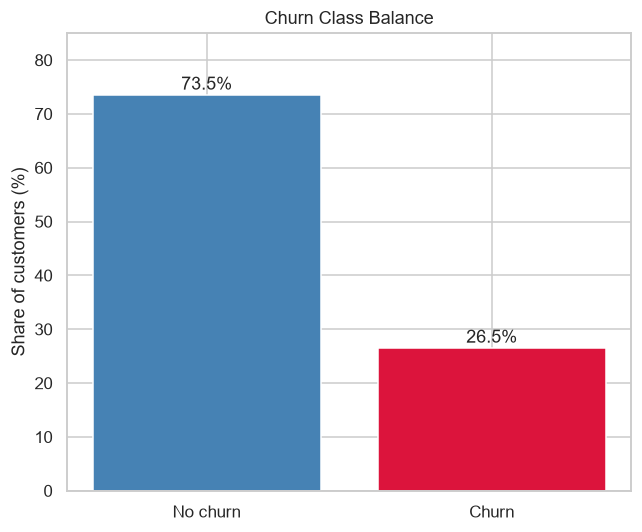

In [3]:
rate = df["Churn_Flag"].value_counts(normalize=True).mul(100).round(1)

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(["No churn", "Churn"], [rate[0], rate[1]], color=["steelblue", "crimson"])
for i, v in enumerate([rate[0], rate[1]]):
    ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_ylabel("Share of customers (%)")
ax.set_title("Churn Class Balance")
ax.set_ylim(0, 85)
plt.tight_layout()
plt.savefig("../charts/class_balance.png")
plt.show()

Only 26.5% of customers churn. A model that predicts "no churn" for everyone would already be right 73.5% of the time. That is the number to beat.

## Step 4 : Encode Text Columns as Numbers

In [4]:
X, y = build_features(df)
print(X.shape)
X.iloc[:3, :8]

(7043, 33)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Total_Services,gender_Male,Partner_Yes,Dependents_Yes
0,0,1,29.85,29.85,1,False,True,False
1,0,34,56.95,1889.50,2,True,False,False
2,0,2,53.85,108.15,2,True,False,False


`get_dummies` turns every text column into 0/1 columns, so the model can use them.

## Step 5 : Train / Test Split

`stratify=y` keeps the churn rate the same (about 26.5%) in both sets.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Churn rate  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")

Train: 5634 | Test: 1409
Churn rate  train: 0.265  test: 0.265


## Step 6 : Baseline

The do-nothing model: predict "no churn" for every customer.

In [6]:
def score(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

baseline_pred = np.zeros(len(y_test), dtype=int)
baseline = score(y_test, baseline_pred)
print(f"Baseline accuracy: {baseline['accuracy']:.3f}")
print(f"Baseline recall:   {baseline['recall']:.3f}   (it never catches a single churner)")

Baseline accuracy: 0.735
Baseline recall:   0.000   (it never catches a single churner)


## Step 7 : Fit Logistic Regression

Scaling is added so the optimizer converges. The pipeline applies it the same way to train and test data.

In [7]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
default = score(y_test, pred)
pd.Series(default).round(3)

accuracy     0.801
precision    0.653
recall       0.529
f1           0.585
dtype: float64

## Step 8 : Confusion Matrix

- **Accuracy**: share of all customers predicted correctly
- **Precision**: of customers flagged as churners, share who really churn
- **Recall**: of customers who really churn, share the model catches
- **F1**: one score balancing precision and recall

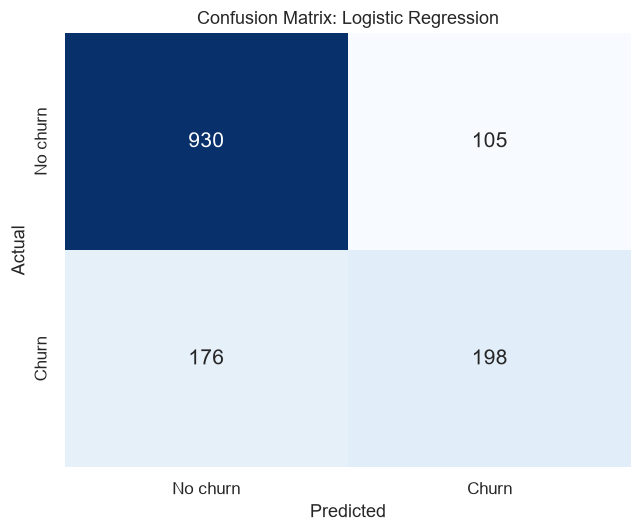

Caught 198 of 374 churners. Missed 176. False alarms: 105.


In [8]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"],
                annot_kws={"size": 14})
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(6, 5))
plot_cm(ax, y_test, pred, "Confusion Matrix: Logistic Regression")
plt.tight_layout()
plt.savefig("../charts/confusion_matrix.png")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"Caught {tp} of {tp + fn} churners. Missed {fn}. False alarms: {fp}.")

Accuracy is 80.1%, which looks good, but it is only 6.6 points above the baseline. The model catches 198 of 374 churners (recall 53%) and misses 176.

## Step 9 : Bonus Mystery Question

Refit with `class_weight="balanced"`. Accuracy drops. Is the model worse?

In [9]:
balanced = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, class_weight="balanced"))
balanced.fit(X_train, y_train)

pred_b = balanced.predict(X_test)
prob_b = balanced.predict_proba(X_test)[:, 1]
bal = score(y_test, pred_b)

results = pd.DataFrame({"Baseline": baseline, "Logistic Regression": default, "Balanced": bal}).T
results["roc_auc"] = [np.nan, roc_auc_score(y_test, prob), roc_auc_score(y_test, prob_b)]
results.round(3)

,accuracy,precision,recall,f1,roc_auc
Baseline,0.735,0.000,0.000,0.000,NaN
Logistic Regression,0.801,0.653,0.529,0.585,0.841
Balanced,0.733,0.498,0.794,0.612,0.841


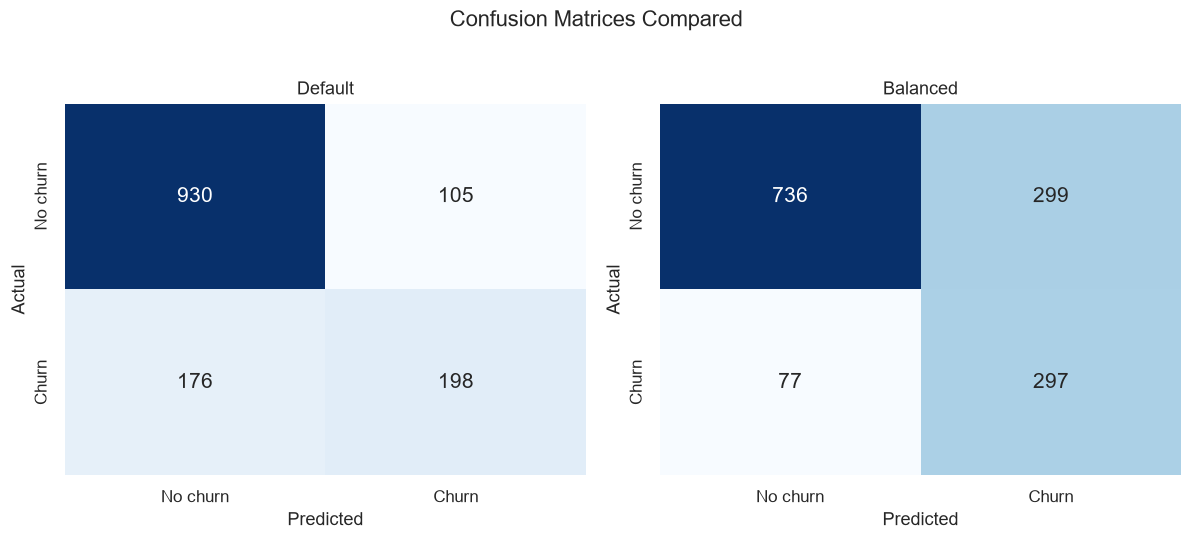

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
plot_cm(axes[0], y_test, pred, "Default")
plot_cm(axes[1], y_test, pred_b, "Balanced")
plt.suptitle("Confusion Matrices Compared", y=1.02)
plt.tight_layout()
plt.savefig("../charts/confusion_matrices_compared.png", bbox_inches="tight")
plt.show()

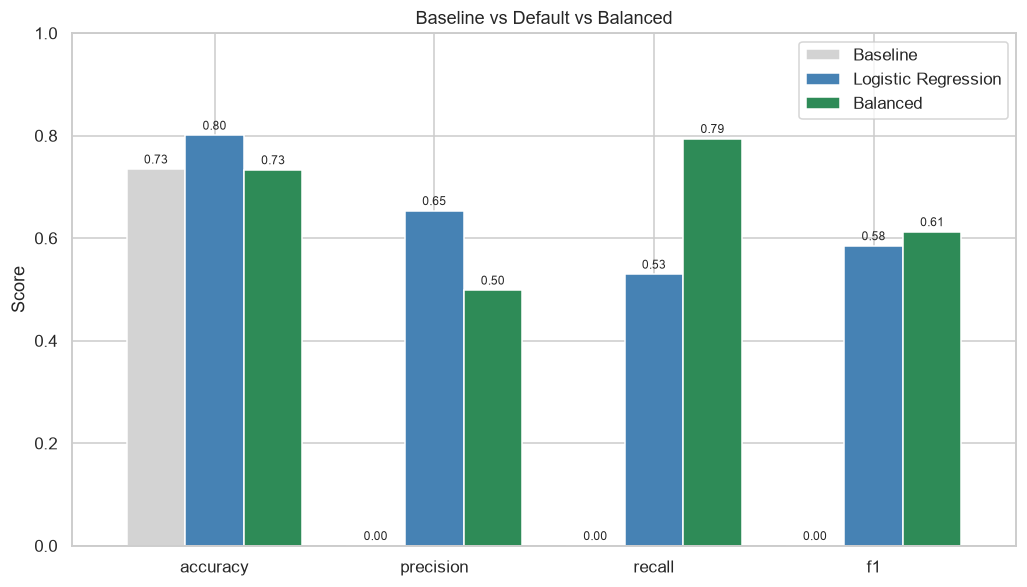

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))
results[["accuracy", "precision", "recall", "f1"]].T.plot(
    kind="bar", ax=ax, rot=0, color=["lightgray", "steelblue", "seagreen"], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.set_ylim(0, 1)
ax.set_title("Baseline vs Default vs Balanced")
ax.set_ylabel("Score")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../charts/metrics_comparison.png")
plt.show()

**Trace-back:**
- Accuracy falls from 80.1% to 73.3%, back to roughly the baseline (73.5%). By accuracy alone the balanced model looks pointless.
- But recall jumps from 53% to 79%: it catches 297 of 374 churners instead of 198, and F1 rises from 0.585 to 0.612.
- The price is false alarms: 299 instead of 105. That is 99 more churners caught for 194 more wasted contacts, about 2 per extra save.
- ROC AUC is 0.841 for both. The model ranks customers equally well. Balancing only moves the cutoff.

The balanced model is not worse, it makes a different trade. If a retention call costs far less than losing a customer, it is the better choice.

## Step 10 : ROC Curve

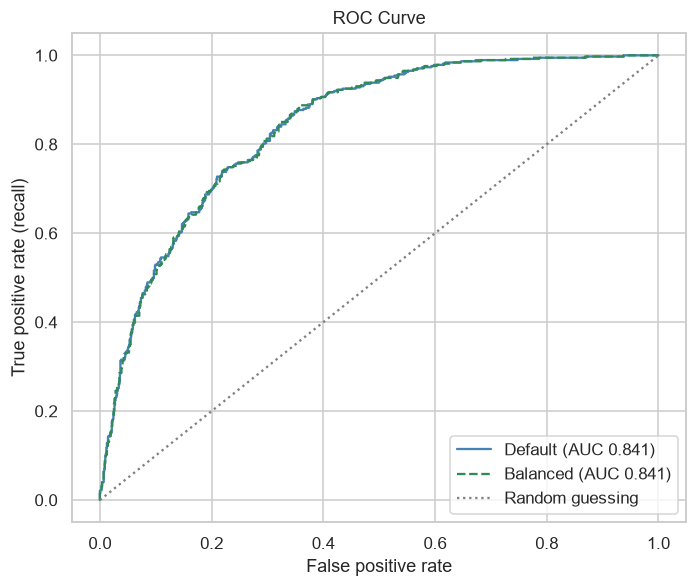

In [12]:
fpr, tpr, _ = roc_curve(y_test, prob)
fpr_b, tpr_b, _ = roc_curve(y_test, prob_b)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(fpr, tpr, label=f"Default (AUC {roc_auc_score(y_test, prob):.3f})", color="steelblue")
ax.plot(fpr_b, tpr_b, label=f"Balanced (AUC {roc_auc_score(y_test, prob_b):.3f})",
        color="seagreen", linestyle="--")
ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC Curve")
ax.legend()
plt.tight_layout()
plt.savefig("../charts/roc_curve.png")
plt.show()

The two curves sit on top of each other. Balancing changes where the cutoff sits on this curve, not the curve itself.

## Step 11 : What Drives Churn?

Raw churn rates by group. Single model coefficients are unreliable here because many columns overlap (MonthlyCharges overlaps with the service columns), so the drivers are read directly from the data.

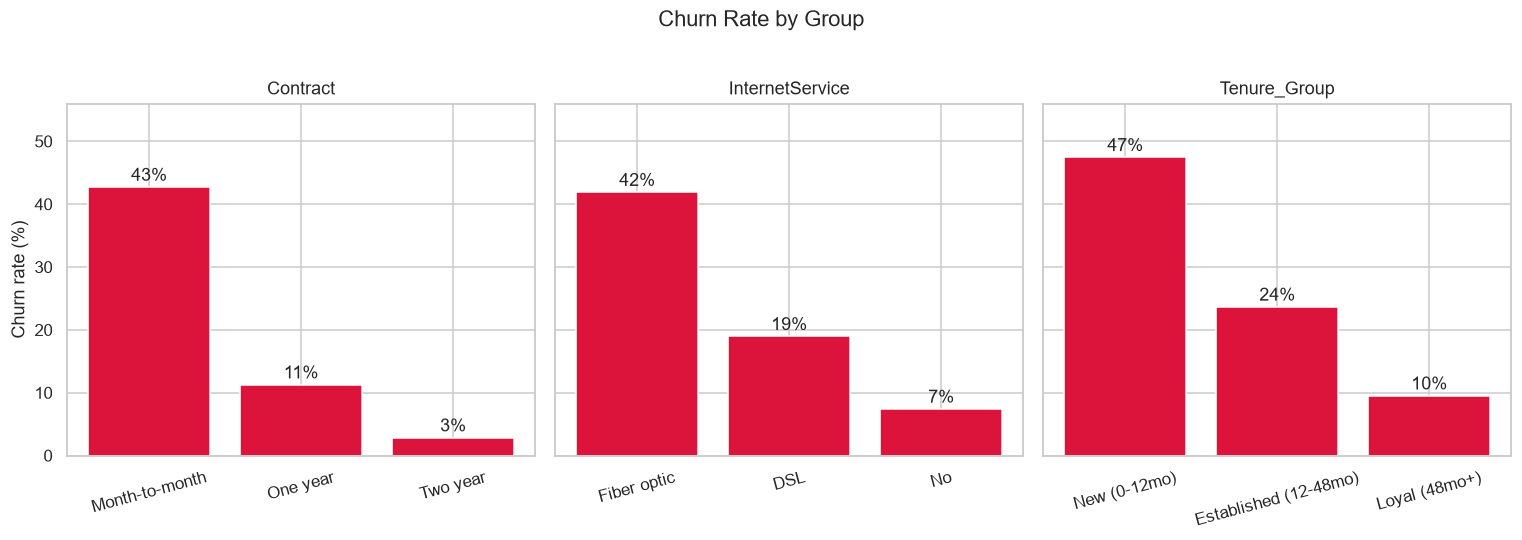

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, col in zip(axes, ["Contract", "InternetService", "Tenure_Group"]):
    rates = df.groupby(col)["Churn_Flag"].mean().mul(100).sort_values(ascending=False)
    ax.bar(rates.index, rates.values, color="crimson")
    for i, v in enumerate(rates.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 56)
plt.suptitle("Churn Rate by Group", y=1.02)
plt.tight_layout()
plt.savefig("../charts/churn_drivers.png", bbox_inches="tight")
plt.show()

Month-to-month churns at 43% vs 3% on two-year contracts. Fiber optic churns at 42% vs 19% for DSL. Customers in their first 12 months churn at 47%.

## Step 12 : Save the Models

In [14]:
joblib.dump({"model": model, "columns": list(X.columns)}, "../model/churn_model_default.joblib")
joblib.dump({"model": balanced, "columns": list(X.columns)}, "../model/churn_model_balanced.joblib")

out = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"],
    "actual_churn": y_test,
    "churn_probability": prob_b.round(3),
    "predicted_churn": pred_b,
})
out.to_csv("../model/test_predictions.csv", index=False)
print("Saved models and test predictions to ../model/")

Saved models and test predictions to ../model/


## Conclusion

Logistic Regression scores 80% accuracy, but doing nothing scores 73.5%, so accuracy alone makes the model look better than it is at the job that matters. It ranks customers well (AUC 0.84), yet at the default cutoff it catches only 53% of churners.

The balanced version catches 79% (297 of 374) while accuracy drops to roughly the baseline. Both rank customers equally well (AUC 0.84). The difference is the cutoff, and the right cutoff depends on what a missed churner costs versus a wasted call.

## Business Recommendations

1. Use the balanced model for retention outreach. It catches 297 of 374 churners instead of 198, at a cost of about 2 extra false alarms per extra churner caught. This is worth it if saving one churner is worth more than about 2 wasted retention calls. If calls or offers are expensive, the default model is the safer choice.
2. Push month-to-month customers toward longer contracts. Churn is 43% on month-to-month, 11% on one year, 3% on two years.
3. Review fiber optic pricing and service quality, and first-year onboarding. Fiber churns at 42% vs 19% on DSL, and customers in their first 12 months churn at 47%. The data shows the gap but not the cause.
4. Report recall and precision next to accuracy. Accuracy alone makes the model look better than it is.